# 10 - Tree models

Goal: use models that can capture non-linear relations (and the salary × job title interaction), with three ways of handling the imbalance. Trees compare each feature to a threshold, so they are trained on the **unscaled** features.

In [2]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.ensemble import BalancedRandomForestClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier
from src.config import SEED
from src.data import load_splits
from src.metrics import evaluate, confusion_rows

sns.set_theme(style='whitegrid')

data, y_train, y_test = load_splits()

## How each model handles the imbalance

- **Balanced Random Forest**: each tree is trained on a bootstrap sample where every class is undersampled to the size of the rarest one.
- **Random Forest with `class_weight='balanced'`**: rare classes weigh more when splits are chosen.
- **XGBoost with `sample_weight`**: each training row gets the weight of its class, so the loss counts rare rows more. XGBoost needs labels starting at 0, so the scores 1-5 are shifted to 0-4.

The class weight is the same formula as in the softmax: $w_c = n / (K\,n_c)$.

In [3]:
w = compute_sample_weight('balanced', y_train)

n, K = len(y_train), y_train.nunique()
formula = n / (K * y_train.value_counts())
assert np.allclose(pd.Series(w, index=y_train.index).groupby(y_train).first(), formula.sort_index())
formula.sort_index().round(3)

Performance_Score
1    31.935
2     3.212
3     0.643
4     0.645
5     0.645
Name: count, dtype: float64

## Training and evaluation

On both feature sets. A balanced logistic regression is included as a reference.

In [5]:
def fit_predict(name, d):
    if name == 'LogReg balanced (ref)':
        m = LogisticRegression(max_iter=5000, class_weight='balanced', random_state=SEED)
        return m.fit(d['X_train_s'], y_train).predict(d['X_test_s'])
    if name == 'Balanced RF':
        m = BalancedRandomForestClassifier(n_estimators=100, sampling_strategy='all', replacement=True,
                                           bootstrap=False, random_state=SEED, n_jobs=-1)
    elif name == 'RF balanced':
        m = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=SEED, n_jobs=-1)
    else:
        m = XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=SEED, n_jobs=-1)
        sw = compute_sample_weight('balanced', y_train) if name == 'XGBoost weighted' else None
        m.fit(d['X_train'], y_train - 1, sample_weight=sw)
        return m.predict(d['X_test']) + 1
    return m.fit(d['X_train'], y_train).predict(d['X_test'])

names = ['LogReg balanced (ref)', 'Balanced RF', 'RF balanced', 'XGBoost unweighted', 'XGBoost weighted']

rows, preds = [], {}
for fs, d in data.items():
    for name in names:
        pred = fit_predict(name, d)
        preds[(fs, name)] = pred
        summary, table = evaluate(y_test, pred)
        rows.append({'features': fs, 'model': name, **summary,
                     'recall_1': table.loc[1, 'recall'], 'recall_2': table.loc[2, 'recall'],
                     'precision_1': table.loc[1, 'precision'], 'precision_2': table.loc[2, 'precision']})

results = pd.DataFrame(rows).set_index(['features', 'model'])
results.round(3)

/Volumes/Mathura SSD/Projets/Employee-Performance-Prediction/.venv/lib/python3.9/site-packages/sklearn/base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(
/Volumes/Mathura SSD/Projets/Employee-Performance-Prediction/.venv/lib/python3.9/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Volumes/Mathura SSD/Projets/Employee-Performance-Prediction/.venv/lib/python3.9/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Volumes/Mathura SSD/Projets/Employee-Performance-Prediction/.venv/lib/python3.9/site-packages/sklearn/base.py:484: FutureWarning: `BaseEstima

accuracy  macro_f1  recall_1  recall_2  \
features  model                                                           
salary    LogReg balanced (ref)     0.261     0.190     0.475     0.155   
          Balanced RF               0.581     0.467     0.338     0.734   
          RF balanced               0.792     0.606     0.025     0.387   
          XGBoost unweighted        0.988     0.933     0.638     0.850   
          XGBoost weighted          0.979     0.909     0.800     0.865   
no_salary LogReg balanced (ref)     0.161     0.146     0.462     0.116   
          Balanced RF               0.235     0.183     0.050     0.250   
          RF balanced               0.309     0.192     0.000     0.000   
          XGBoost unweighted        0.310     0.192     0.000     0.000   
          XGBoost weighted          0.247     0.189     0.062     0.179   

                                 precision_1  precision_2  
features  model                                            
salary    LogReg balanced (ref)        0.013        0.075  
          Balanced RF                  0.034        0.190  
          RF balanced                  1.000        0.994  
          XGBoost unweighted           1.000        0.959  
          XGBoost weighted             0.681        0.811  
no_salary LogReg balanced (ref)        0.007        0.051  
          Balanced RF                  0.006        0.066  
          RF balanced                  0.000        0.000  
          XGBoost unweighted           0.000        0.000  
          XGBoost weighted             0.006        0.060

## Confusion matrices of the weighted XGBoost

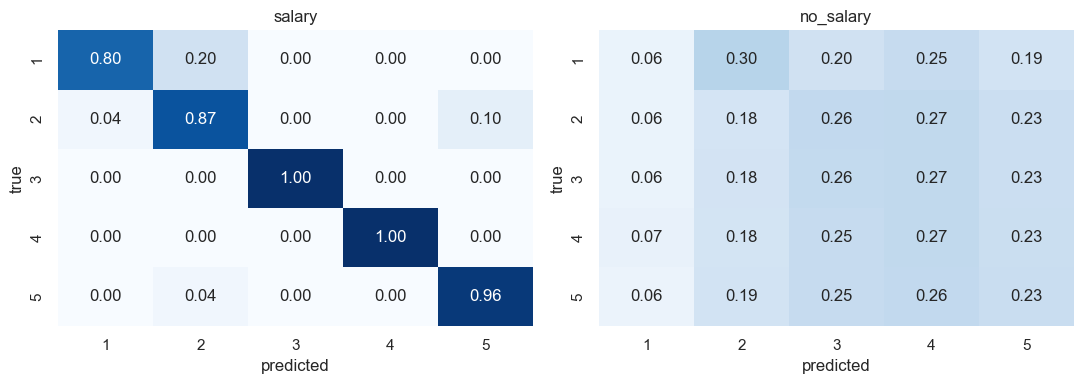

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, fs in zip(axes, data):
    sns.heatmap(confusion_rows(y_test, preds[(fs, 'XGBoost weighted')]), annot=True, fmt='.2f',
                cmap='Blues', vmin=0, vmax=1, ax=ax, cbar=False)
    ax.set_title(fs); ax.set_xlabel('predicted'); ax.set_ylabel('true')
plt.tight_layout()
plt.show()

## Ablation: adding the job title

Salary alone is ambiguous: the same salary can come from different job titles with different scores (6000 = Analyst × 1.5 = Developer × 1.2). With the job title, `salary / (1 + 0.1 × score)` is exactly the job's base salary, so the score can be decoded. Weighted XGBoost with the `Job_Title` dummies:

In [7]:
data_job, _, _ = load_splits(with_job_title=True)
rows_job = []
for fs, d in data_job.items():
    pred = fit_predict('XGBoost weighted', d)
    summary, table = evaluate(y_test, pred)
    rows_job.append({'features': fs + ' + Job_Title', **summary,
                     'recall_1': table.loc[1, 'recall'], 'recall_2': table.loc[2, 'recall']})
pd.DataFrame(rows_job).set_index('features').round(3)

,accuracy,macro_f1,recall_1,recall_2
features,,,,
salary + Job_Title,1.000,1.000,1.000,1.000
no_salary + Job_Title,0.241,0.184,0.062,0.176
